# Predicting the Probability of Something Occurring

With a linear regression, we were attempting to predict a response variable (y) with some predictor variables (X). 

$$ Y = \beta_0 + \beta_1 X $$

What if we wanted to create a linear regression to predict the **probability** of something either occurring (Y=1) or not occurring (Y=0) based on some predictor variables $X$? 

$$P(X) = Pr(Y=1 \, | \, X)$$

which we read as "The probability of the response variable $y$ occurring given predictor variable $X$"

The linear regression will not work, so we need a function with properties better suited to probabilities...

## Standard Logistic Function

The standard logistic function is defined as:

$$ y = \frac{e^x}{1+e^x} $$

This appears as an "s" shape and is also known as a sigmoid curve.

*Note this is NOT the logarithmic function!*

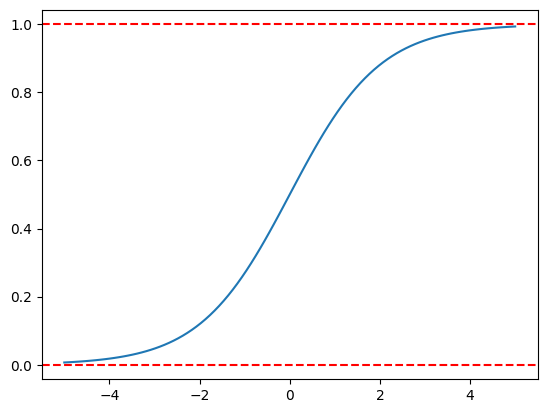

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)
x = np.linspace(-5, 5, 100)
logistic_y = ( math.e**x ) / (1 + math.e**x)
ax.plot(x, logistic_y)
plt.axhline(y=0, color='r', linestyle='--')
plt.axhline(y=1, color='r', linestyle='--')

## Logistic Regression

The standard logistic curve takes continuous values and returns values bounded between 0 and 1, making it perfect to take continuous predictor variables and output a probability based on those predictors. 

$$ P(X) = \frac{e^{\beta_0 + \beta_1 X}}{1+e^{\beta_0 + \beta_1 X}} $$

### Reasoning Behind Logisitic Regression Equation

Why set up the linear regression as the variable in the logistic regression? Let's try to solve for $e^{\beta_0 + \beta_1 X}$ and see what happens. Let's start by noticing something about $\frac{1}{P(X)}$.

$$ \frac{1}{P(X)} = \frac{1+e^{\beta_0 + \beta_1 X}}{e^{\beta_0 + \beta_1 X}} = \frac{1}{e^{\beta_0 + \beta_1 X}} + 1 $$

We only have one $e^{\beta_0 + \beta_1 X}$ term now! So we can solve for it. 

$$ \frac{1}{P(X)} - 1 = \frac{1}{e^{\beta_0 + \beta_1 X}} $$

Combine the left side into a single fraction:

$$ \frac{1-P(X)}{P(X)} = \frac{1}{e^{\beta_0 + \beta_1 X}} $$

And flip the fractions to solve for $e^{\beta_0 + \beta_1 X}$:

$$ \frac{P(X)}{1-P(X)} = e^{\beta_0 + \beta_1 X} $$

Now we can take the logarithm of both sides to arrive at our linear regression:

$$ \log \left( \frac{P(X)}{1-P(X)} \right) = \beta_0 + \beta_1 X $$

The left side is called the *log odds* or *logit*, which is why the logistic regression is sometimes shorthanded to the *logit* regression. 

We can then set a cutoff probability and assign values to the left of the cutoff as "0" and to the right of the cutoff as "1".

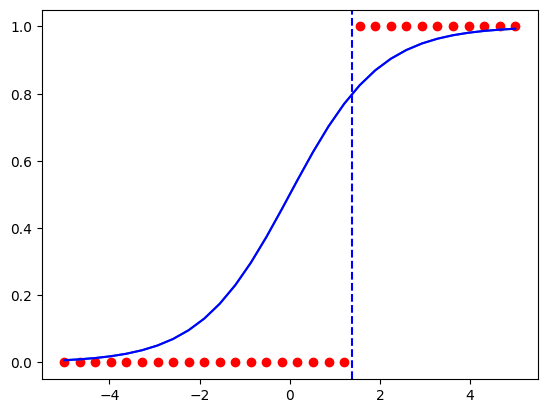

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt

# We will use sympy to solve for the x-value associated with our cutoff probability in order to graph it
from sympy import symbols, Eq, solve

x = np.linspace(-5, 5, 30)
logistic_y = ( math.e**x ) / (1 + math.e**x)

fig, ax = plt.subplots(1, 1)
ax.plot(x, logistic_y)

# initalize empty sets to classify our x-values into
classified_as_0 = []
classified_as_1 = []

cutoff = 0.8
# We'll define x_c as our variable since we are already using x as our set of x-values
x_c = symbols('x_c')
cutoff_equation = Eq(cutoff, ( math.e**x_c ) / (1 + math.e**x_c))
x_value_for_cutoff = solve(cutoff_equation, x_c)[0]

for x_value in x:
    if ( ( math.e**x_value ) / (1 + math.e**x_value) ) >= cutoff:
        classified_as_1.append(x_value)
    else:
        classified_as_0.append(x_value)

plt.axvline(x=x_value_for_cutoff, color='b', linestyle='--')
ax.plot(x, logistic_y, color='b')
ax.scatter(classified_as_0, np.full((len(classified_as_0), 1), 0), color='r')
ax.scatter(classified_as_1, np.full((len(classified_as_1), 1), 1), color='r')

### Estimating Logistic Regression Coefficients - Maximum Likelihood

While we may be inclined to see if the ordinary least squares (OLS) method would work here, an alternative called *maximum likelihood* should be used. Similar to the OLS method, we'd: 
- Crete a "likelihood" function based on the expected and actual probability, 
- Take the derivative of the likelihood function, 
- Set the derivative equal to 0, and 
- Solve for the maximum. 

The mathematics behind how to do this is beyond even an introductory graduate-level Data Science course, so we won't touch it. 

## Maximum Likelihood Regression Results

Python and Excel will again run the full results for you. Let's use the diabetes data to test how this looks.

### Prepare Data

In [3]:
import numpy as np
import pandas as pd
import os

import statsmodels.api as sm

diabetes_file_path = os.path.join(os.getcwd(), 'datasets', 'Diabetes_and_LifeStyle_Dataset.csv')
diabetes_df = pd.read_csv(diabetes_file_path)

diabetes_response_var = diabetes_df['diagnosed_diabetes']
# For now, we will take numeric variables only
numeric_vars = ['Age', 'alcohol_consumption_per_week',
       'physical_activity_minutes_per_week', 'diet_score',
       'sleep_hours_per_day', 'screen_time_hours_per_day',
       'family_history_diabetes', 'hypertension_history',
       'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp',
       'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol',
       'ldl_cholesterol', 'triglycerides', 'glucose_fasting',
       'glucose_postprandial', 'insulin_level', 'hba1c',
       'diabetes_risk_score']
diabetes_predictor_vars = diabetes_df[numeric_vars]

### Build Logit Regression

In [4]:
diabetes_predictor_vars_with_constant = sm.add_constant(diabetes_predictor_vars)
logit_model = sm.Logit(diabetes_response_var, diabetes_predictor_vars_with_constant)
logit_regression = logit_model.fit()

Optimization terminated successfully.
         Current function value: 0.347636
         Iterations 8


### Logit Regression Summary

In [5]:
logit_regression.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:     diagnosed_diabetes   No. Observations:                97297
Model:                          Logit   Df Residuals:                    97273
Method:                           MLE   Df Model:                           23
Date:                Wed, 29 Jul 2026   Pseudo R-squ.:                  0.4835
Time:                        15:28:49   Log-Likelihood:                -33824.
converged:                       True   LL-Null:                       -65480.
Covariance Type:            nonrobust   LLR p-value:                     0.000
======================================================================================================
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                -24.0263      0.338    -71.056      0.000     -24.689     -23.364
Age                                    0.0003      0.003      0.086      0.931      -0.006       0.007
alcohol_consumption_per_week          -0.0094      0.007     -1.365      0.172      -0.023       0.004
physical_activity_minutes_per_week    -0.0001      0.000     -0.345      0.730      -0.001       0.001
diet_score                             0.0017      0.008      0.215      0.830      -0.014       0.018
sleep_hours_per_day                   -0.0083      0.009     -0.939      0.348      -0.026       0.009
screen_time_hours_per_day             -0.0044      0.005     -0.870      0.384      -0.014       0.006
family_history_diabetes                0.0345      0.191      0.181      0.857      -0.340       0.409
hypertension_history                  -0.0133      0.023     -0.585      0.558      -0.058       0.031
cardiovascular_history                 0.0502      0.037      1.364      0.173      -0.022       0.122
bmi                                   -0.0002      0.007     -0.032      0.974      -0.014       0.014
waist_to_hip_ratio                     0.3902      0.320      1.218      0.223      -0.238       1.018
systolic_bp                            0.0007      0.001      0.783      0.433      -0.001       0.002
diastolic_bp                          -0.0015      0.001     -1.252      0.210      -0.004       0.001
heart_rate                            -0.0004      0.001     -0.325      0.745      -0.003       0.002
cholesterol_total                     -0.0004      0.001     -0.472      0.637      -0.002       0.001
hdl_cholesterol                       -0.0006      0.002     -0.349      0.727      -0.004       0.003
ldl_cholesterol                        0.0009      0.001      0.973      0.331      -0.001       0.003
triglycerides                          0.0002      0.000      0.643      0.520      -0.000       0.001
glucose_fasting                        0.0154      0.001     14.025      0.000       0.013       0.018
glucose_postprandial                 4.47e-05      0.001      0.050      0.960      -0.002       0.002
insulin_level                         -0.0007      0.002     -0.311      0.756      -0.005       0.004
hba1c                                  3.4236      0.043     79.129      0.000       3.339       3.508
diabetes_risk_score                    0.0236      0.012      1.993      0.046       0.000       0.047
======================================================================================================
"""

Like the Linear Regression summary, we have a table with our predictor variables, their coefficients, and a t-test for each. Scanning through the list we see some predictors that we would definitely reject that they are independent from predicting diabetes: *glucose_fasting* and *hba1c*. For an alpha of 0.05 we would also reject independence for *diabetes_risk_score*.

Let's quickly build another model with just these 3 predictors to compare the Log-Likelihood (since all we know is we want to maximize it). 

### Second Logisitic Regression

In [6]:
stat_sig_predictor_names = ['glucose_fasting', 'hba1c', 'diabetes_risk_score']
diabetes_stat_sig_predictor_vars = diabetes_df[stat_sig_predictor_names]

stat_sig_predictor_vars_with_constant = sm.add_constant(diabetes_stat_sig_predictor_vars)
stat_sig_logit_model = sm.Logit(diabetes_response_var, stat_sig_predictor_vars_with_constant)
stat_sig_logit_regression = stat_sig_logit_model.fit()

stat_sig_logit_regression.summary()

Optimization terminated successfully.
         Current function value: 0.347726
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:     diagnosed_diabetes   No. Observations:                97297
Model:                          Logit   Df Residuals:                    97293
Method:                           MLE   Df Model:                            3
Date:                Wed, 29 Jul 2026   Pseudo R-squ.:                  0.4833
Time:                        15:28:49   Log-Likelihood:                -33833.
converged:                       True   LL-Null:                       -65480.
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 -23.9450      0.160   -149.418      0.000     -24.259     -23.631
glucose_fasting         0.0154      0.001     14.417      0.000       0.013       0.018
hba1c                   3.4248      0.026    134.069      0.000       3.375       3.475
diabetes_risk_score     0.0267      0.001     21.432      0.000       0.024       0.029
=======================================================================================
"""

### Third Logisitic Regression

In [10]:
best_predictor_name = ['hba1c']
diabetes_best_predictor_vars = diabetes_df[best_predictor_name]

best_predictor_vars_with_constant = sm.add_constant(diabetes_best_predictor_vars)
best_predictor_logit_model = sm.Logit(diabetes_response_var, best_predictor_vars_with_constant)
best_predictor_logit_regression = best_predictor_logit_model.fit()

best_predictor_logit_regression.summary()

Optimization terminated successfully.
         Current function value: 0.352925
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:     diagnosed_diabetes   No. Observations:                97297
Model:                          Logit   Df Residuals:                    97295
Method:                           MLE   Df Model:                            1
Date:                Wed, 29 Jul 2026   Pseudo R-squ.:                  0.4756
Time:                        15:48:15   Log-Likelihood:                -34339.
converged:                       True   LL-Null:                       -65480.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -22.8567      0.150   -152.370      0.000     -23.151     -22.563
hba1c          3.6409      0.024    154.085      0.000       3.595       3.687
==============================================================================
"""

### Model Results

We can look at each coefficient's magnitude to determine its importance to the logit regression model. For our model, 'hba1c' is far larger than our other two predictor variables and appears to be the major predictive influence for the model. 

### Model Evaluation Results

- **Pseudo R-squared**: While a logistic regression does not have a "true" R-squared, there is a way to create a comparative measure. As before this ranges from 0 to 1, and a score closer to 1 indicates a better model fit of the data. 
- **Log-Likelihood**: This is an error-like measure for logistic functions to measure how well the model's predicted probabilities line up with the actual observations, with log-likelihood of 0 being a perfect match. We'll use this to compare models to determine a "best" one. We'd like to minimize this error as much as possible (which means we want the max log-likelihood across models).
- **LL-Null**: Like the F-test can be used to evaluate an entire linear regression, a *Log-Likelihood* (LL) hypothesis test assumes the model only needs the constant coefficient. Our alternative is that including at least one of the predictor variables creates a better fitting predictive model. 
$$ H_0: P(X) = \frac{e^{\beta_0}}{1+e^{\beta_0}} $$
- **LLR p-value**: The *Log-Likelihood Ratio* (LLR) is the test statistic we create to find an associated p-value. 

In the case of our model here, we have statistically significant evidence that at least one of our predictor variables creates a better model than none. In a later module we'll look at ways to measure how well this "statistically significant" model predicts diabetes in a patient.